# AI-Based Customer Spending Prediction

## Project Overview

This project uses Machine Learning to predict whether a customer belongs to a Low, Medium, or High spending category based on their demographic information and purchasing behaviour.

## Objectives

* Prepare and clean a customer dataset.
* Perform Exploratory Data Analysis (EDA).
* Create meaningful visualizations.
* Train Decision Tree and Random Forest classification models.
* Evaluate and compare model performance.
* Predict spending categories for new customers.
* Identify important factors that influence customer spending.

## Technologies Used

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn
* Scikit-learn
* Jupyter Notebook

## Expected Outcome

A machine learning system that classifies customers into spending categories and provides useful insights into customer purchasing behaviour.


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [10]:
np.random.seed(42)

n = 200

df = pd.DataFrame({
    "CustomerID": range(1, n + 1),
    "Age": np.random.randint(18, 66, n),
    "AnnualIncome": np.random.randint(20000, 150001, n),
    "SpendingScore": np.random.randint(1, 101, n),
    "PurchasesPerMonth": np.random.randint(1, 16, n),
    "AverageOrderValue": np.random.randint(200, 5001, n)
})

df["SpendingCategory"] = pd.cut(
    df["SpendingScore"],
    bins=[0, 40, 70, 100],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

df.head()

,CustomerID,Age,AnnualIncome,SpendingScore,PurchasesPerMonth,AverageOrderValue,SpendingCategory
0,1,56,88840,35,12,4375,Low
1,2,46,138451,64,13,3133,Medium
2,3,32,74384,49,13,3484,Medium
3,4,60,71005,17,12,4498,Low
4,5,25,66576,44,15,3011,Medium


In [11]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nSpending Category Distribution:")
print(df["SpendingCategory"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (200, 7)

Column Names:
['CustomerID', 'Age', 'AnnualIncome', 'SpendingScore', 'PurchasesPerMonth', 'AverageOrderValue', 'SpendingCategory']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   CustomerID         200 non-null    int64   
 1   Age                200 non-null    int32   
 2   AnnualIncome       200 non-null    int32   
 3   SpendingScore      200 non-null    int32   
 4   PurchasesPerMonth  200 non-null    int32   
 5   AverageOrderValue  200 non-null    int32   
 6   SpendingCategory   200 non-null    category
dtypes: category(1), int32(5), int64(1)
memory usage: 5.9 KB

Statistical Summary:


,CustomerID,Age,AnnualIncome,SpendingScore,PurchasesPerMonth,AverageOrderValue
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,41.785000,85020.880000,51.065000,8.255000,2774.570000
std,57.879185,13.836038,38238.093685,29.115793,4.276848,1411.718617
min,1.000000,18.000000,20854.000000,1.000000,1.000000,209.000000
25%,50.750000,30.000000,54740.000000,25.000000,4.000000,1586.500000
50%,100.500000,42.000000,84526.000000,51.000000,9.000000,2934.500000
75%,150.250000,54.000000,116922.750000,71.000000,12.000000,4042.250000
max,200.000000,65.000000,149307.000000,100.000000,15.000000,4984.000000



Spending Category Distribution:
SpendingCategory
Low       78
Medium    72
High      50
Name: count, dtype: int64

Missing Values:
CustomerID           0
Age                  0
AnnualIncome         0
SpendingScore        0
PurchasesPerMonth    0
AverageOrderValue    0
SpendingCategory     0
dtype: int64


In [12]:
# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Handle missing values
df.dropna(inplace=True)

# Reset the index
df.reset_index(drop=True, inplace=True)

print("\nDataset cleaned successfully!")
print("Final dataset shape:", df.shape)

# Verify missing values
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Duplicate rows: 0

Dataset cleaned successfully!
Final dataset shape: (200, 7)

Missing values after cleaning:
CustomerID           0
Age                  0
AnnualIncome         0
SpendingScore        0
PurchasesPerMonth    0
AverageOrderValue    0
SpendingCategory     0
dtype: int64


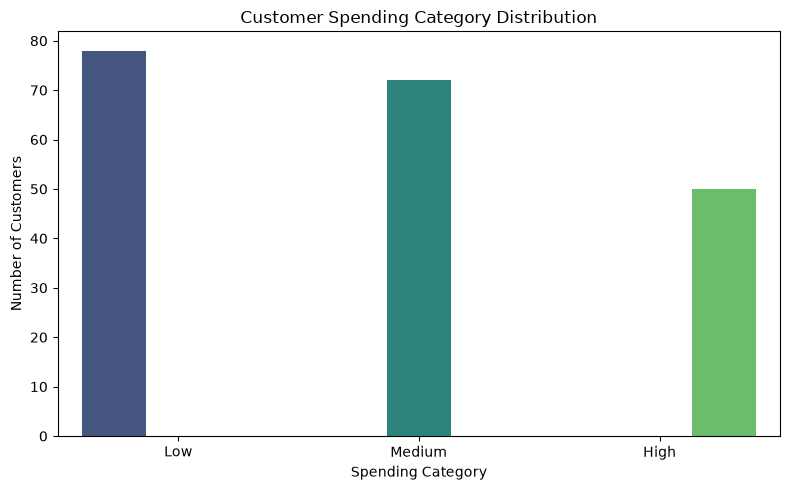

In [13]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="SpendingCategory",
    hue="SpendingCategory",
    order=["Low", "Medium", "High"],
    palette="viridis",
    legend=False
)

plt.title("Customer Spending Category Distribution")
plt.xlabel("Spending Category")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

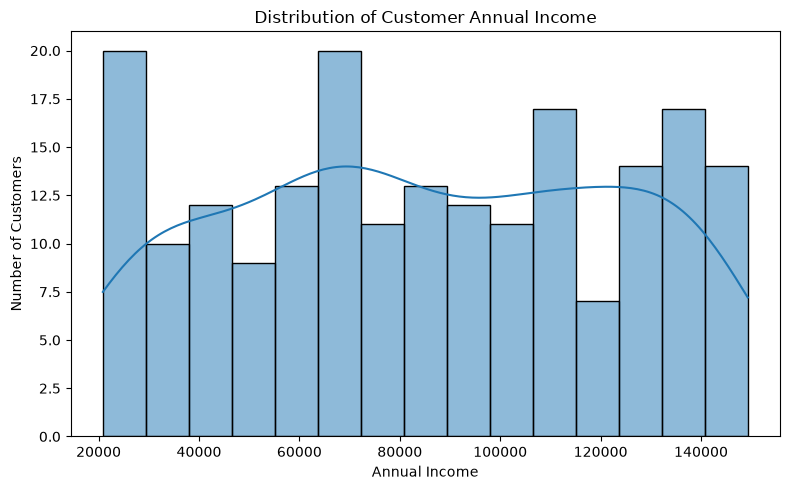

In [14]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="AnnualIncome", bins=15, kde=True)

plt.title("Distribution of Customer Annual Income")
plt.xlabel("Annual Income")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

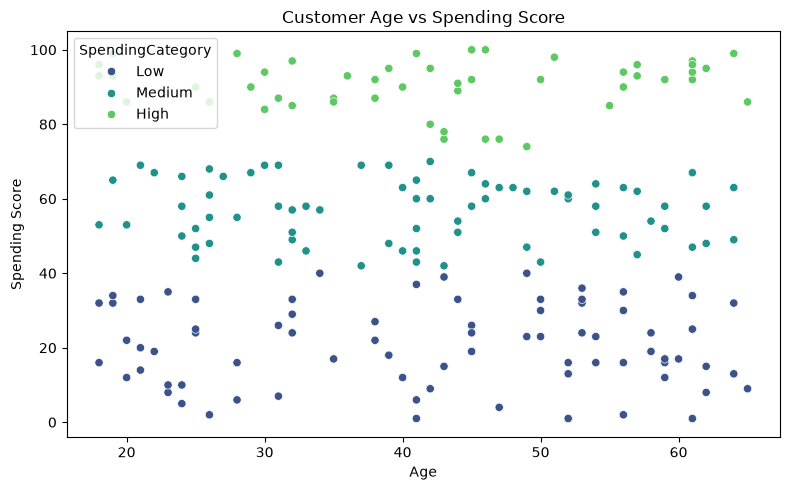

In [15]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="SpendingScore",
    hue="SpendingCategory",
    hue_order=["Low", "Medium", "High"],
    palette="viridis"
)

plt.title("Customer Age vs Spending Score")
plt.xlabel("Age")
plt.ylabel("Spending Score")
plt.tight_layout()
plt.show()

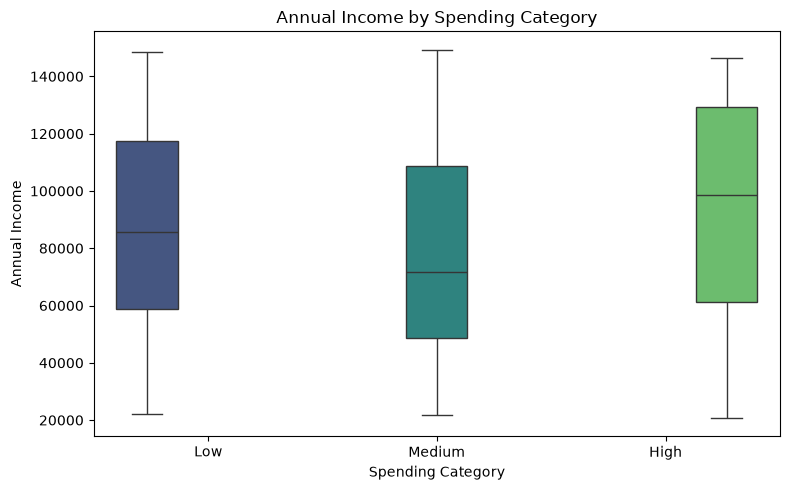

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="SpendingCategory",
    y="AnnualIncome",
    order=["Low", "Medium", "High"],
    hue="SpendingCategory",
    palette="viridis",
    legend=False
)

plt.title("Annual Income by Spending Category")
plt.xlabel("Spending Category")
plt.ylabel("Annual Income")

plt.tight_layout()
plt.show()

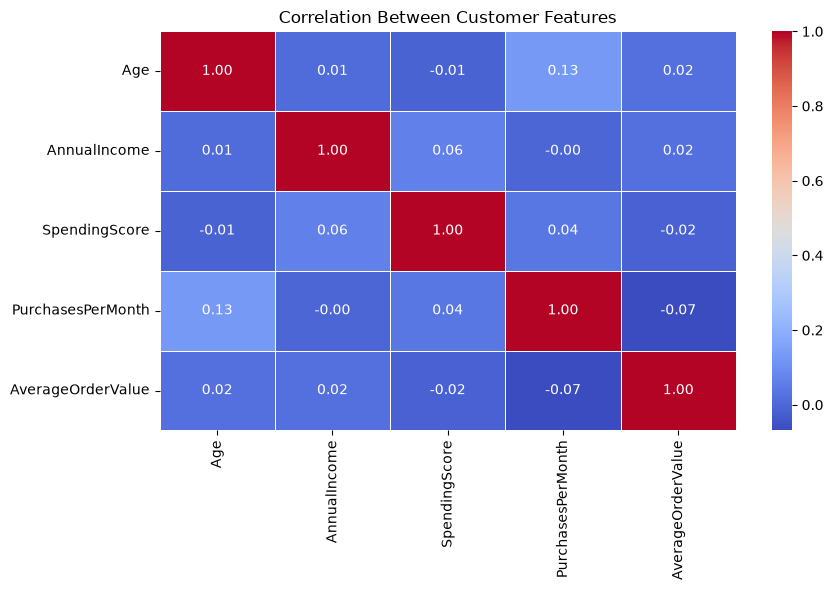

In [17]:
numeric_features = [
    "Age",
    "AnnualIncome",
    "SpendingScore",
    "PurchasesPerMonth",
    "AverageOrderValue"
]

correlation_matrix = df[numeric_features].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Customer Features")
plt.tight_layout()
plt.show()

In [18]:
# Select input features
X = df[
    [
        "Age",
        "AnnualIncome",
        "PurchasesPerMonth",
        "AverageOrderValue"
    ]
]

# Select the target variable
y = df["SpendingCategory"].astype(str)

print("Input features selected:")
print(X.head())

print("\nTarget variable:")
print(y.head())

print("\nNumber of input features:", X.shape[1])
print("Number of records:", X.shape[0])

Input features selected:
   Age  AnnualIncome  PurchasesPerMonth  AverageOrderValue
0   56         88840                 12               4375
1   46        138451                 13               3133
2   32         74384                 13               3484
3   60         71005                 12               4498
4   25         66576                 15               3011

Target variable:
0       Low
1    Medium
2    Medium
3       Low
4    Medium
Name: SpendingCategory, dtype: str

Number of input features: 4
Number of records: 200


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training records: 160
Testing records: 40

Training data shape: (160, 4)
Testing data shape: (40, 4)


In [20]:
decision_tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

decision_tree.fit(X_train, y_train)

dt_predictions = decision_tree.predict(X_test)

print("Decision Tree Model trained successfully!")
print("Number of predictions:", len(dt_predictions))

Decision Tree Model trained successfully!
Number of predictions: 40


In [21]:
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest.fit(X_train, y_train)

rf_predictions = random_forest.predict(X_test)

print("Random Forest Model trained successfully!")
print("Number of predictions:", len(rf_predictions))

Random Forest Model trained successfully!
Number of predictions: 40


In [22]:
def evaluate_model(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }


results = [
    evaluate_model("Decision Tree", y_test, dt_predictions),
    evaluate_model("Random Forest", y_test, rf_predictions)
]

results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.300,0.312,0.300,0.288
1,Random Forest,0.375,0.401,0.375,0.379


In [23]:
print("DECISION TREE CLASSIFICATION REPORT")
print("=" * 45)
print(classification_report(
    y_test,
    dt_predictions,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

print("\nRANDOM FOREST CLASSIFICATION REPORT")
print("=" * 45)
print(classification_report(
    y_test,
    rf_predictions,
    labels=["Low", "Medium", "High"],
    zero_division=0
))

DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Low       0.38      0.19      0.25        16
      Medium       0.33      0.50      0.40        14
        High       0.18      0.20      0.19        10

    accuracy                           0.30        40
   macro avg       0.30      0.30      0.28        40
weighted avg       0.31      0.30      0.29        40


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Low       0.58      0.44      0.50        16
      Medium       0.30      0.43      0.35        14
        High       0.25      0.20      0.22        10

    accuracy                           0.38        40
   macro avg       0.38      0.36      0.36        40
weighted avg       0.40      0.38      0.38        40



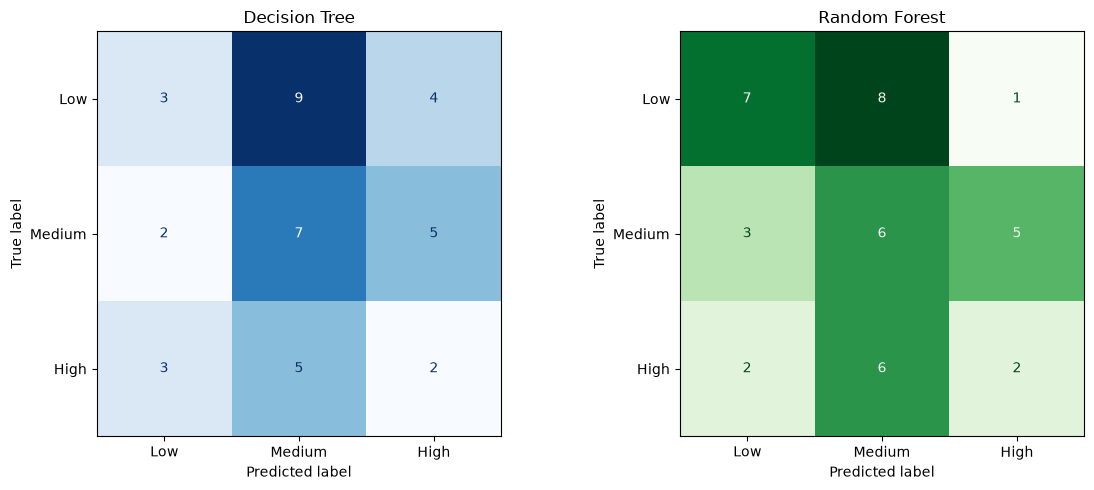

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

labels = ["Low", "Medium", "High"]

ConfusionMatrixDisplay(
    confusion_matrix(y_test, dt_predictions, labels=labels),
    display_labels=labels
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Decision Tree")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, rf_predictions, labels=labels),
    display_labels=labels
).plot(ax=axes[1], cmap="Greens", colorbar=False)

axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

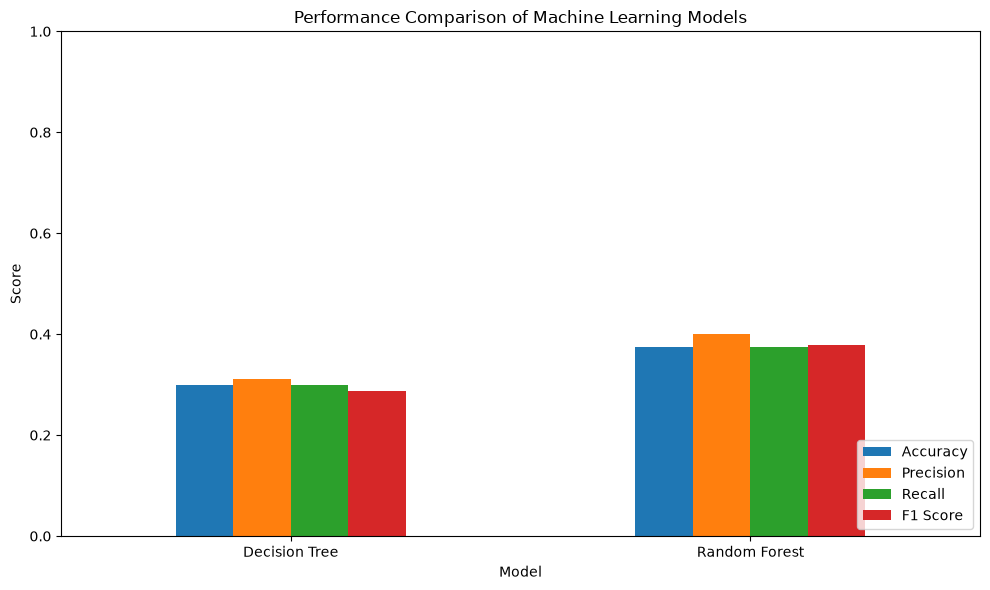

Best model based on F1 Score: Random Forest


In [25]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Performance Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_model_name = results_df.loc[
    results_df["F1 Score"].idxmax(), "Model"
]

print("Best model based on F1 Score:", best_model_name)

In [26]:
# Select the best-performing model
if best_model_name == "Decision Tree":
    best_model = decision_tree
else:
    best_model = random_forest


# Create a function to predict customer spending
def predict_customer_spending(
    age,
    annual_income,
    purchases_per_month,
    average_order_value
):
    customer = pd.DataFrame([{
        "Age": age,
        "AnnualIncome": annual_income,
        "PurchasesPerMonth": purchases_per_month,
        "AverageOrderValue": average_order_value
    }])

    prediction = best_model.predict(customer)[0]

    return prediction


# Test with a new customer
prediction = predict_customer_spending(
    age=30,
    annual_income=65000,
    purchases_per_month=8,
    average_order_value=1500
)

print("NEW CUSTOMER DETAILS")
print("-" * 30)
print("Age: 30")
print("Annual Income: ₹65,000")
print("Purchases Per Month: 8")
print("Average Order Value: ₹1,500")

print("\nPredicted Spending Category:", prediction)

NEW CUSTOMER DETAILS
------------------------------
Age: 30
Annual Income: ₹65,000
Purchases Per Month: 8
Average Order Value: ₹1,500

Predicted Spending Category: Medium


,Feature,Decision Tree,Random Forest
0,Age,0.120,0.227
1,AnnualIncome,0.322,0.276
2,PurchasesPerMonth,0.051,0.195
3,AverageOrderValue,0.507,0.302


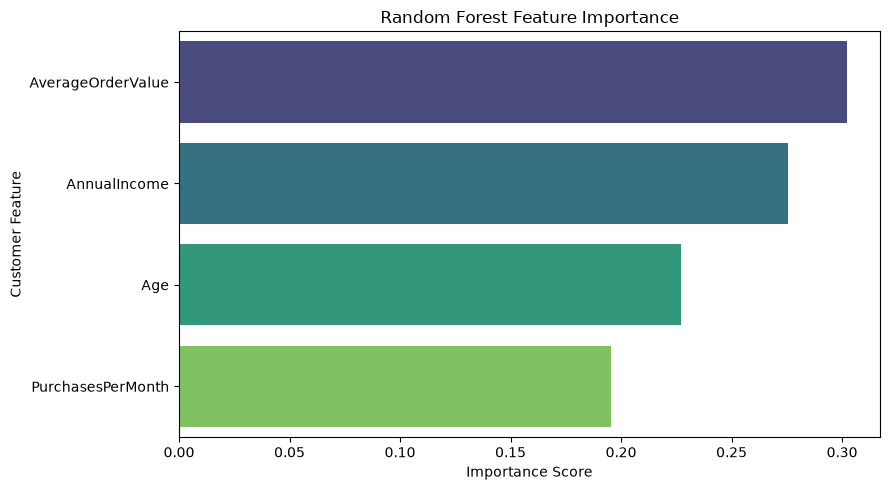

In [27]:
# Get feature importance from both models
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Decision Tree": decision_tree.feature_importances_,
    "Random Forest": random_forest.feature_importances_
})

display(feature_importance.round(3))

# Visualize Random Forest feature importance
plt.figure(figsize=(9, 5))

sns.barplot(
    data=feature_importance.sort_values(
        "Random Forest", ascending=False
    ),
    x="Random Forest",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Customer Feature")
plt.tight_layout()
plt.show()

In [28]:
print("=" * 50)
print("AI-BASED CUSTOMER SPENDING PREDICTION")
print("=" * 50)

print("\n1. DATASET SUMMARY")
print("-" * 30)
print("Total customers:", len(df))
print("Total input features:", X.shape[1])
print("Spending categories:", df["SpendingCategory"].nunique())

print("\n2. SPENDING CATEGORY DISTRIBUTION")
print("-" * 30)
print(df["SpendingCategory"].value_counts())

print("\n3. MODEL PERFORMANCE")
print("-" * 30)
display(results_df.round(3))

print("\n4. BEST MODEL")
print("-" * 30)
print("Selected model:", best_model_name)

print("\n5. SAMPLE CUSTOMER PREDICTION")
print("-" * 30)
print("Predicted category:", prediction)

print("\nProject analysis completed successfully!")

AI-BASED CUSTOMER SPENDING PREDICTION

1. DATASET SUMMARY
------------------------------
Total customers: 200
Total input features: 4
Spending categories: 3

2. SPENDING CATEGORY DISTRIBUTION
------------------------------
SpendingCategory
Low       78
Medium    72
High      50
Name: count, dtype: int64

3. MODEL PERFORMANCE
------------------------------


,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.300,0.312,0.300,0.288
1,Random Forest,0.375,0.401,0.375,0.379



4. BEST MODEL
------------------------------
Selected model: Random Forest

5. SAMPLE CUSTOMER PREDICTION
------------------------------
Predicted category: Medium

Project analysis completed successfully!


## Conclusion

The AI-Based Customer Spending Prediction project demonstrates how machine learning can be used to classify customers into Low, Medium, and High spending categories.

A synthetic dataset was created and analyzed using Python, Pandas, NumPy, Matplotlib, and Seaborn. Exploratory data analysis was performed to understand the dataset and visualize customer characteristics.

Two machine learning algorithms, Decision Tree and Random Forest, were trained and evaluated using accuracy, precision, recall, F1-score, classification reports, and confusion matrices. Feature importance was also examined, and a sample prediction function was developed for new customer records.

The current dataset is randomly generated, so the models cannot reliably predict actual customer spending behavior. A real-world implementation would require representative customer data and spending categories meaningfully related to the input features.

This project provided practical experience in data preprocessing, visualization, classification, model evaluation, and applying machine learning to a customer analytics problem.
